This is a test case by Vince Maes.

It has roughly the same output as reported by him, giving at least some assurances that the code is correct.
(In fact, initially, it did not give the same output and we are highly grateful to Vince for helping us find and fix the issue)

TODO: insert paper reference for the data

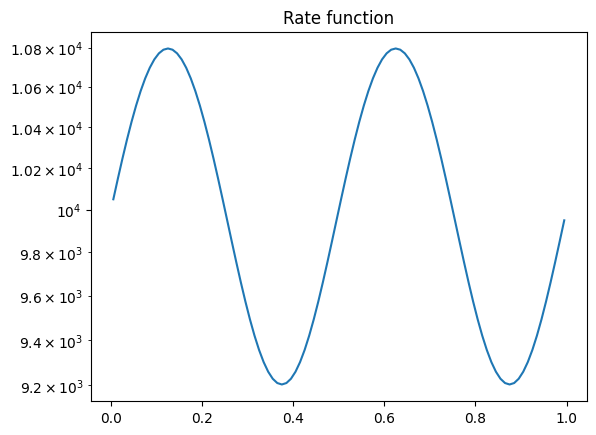

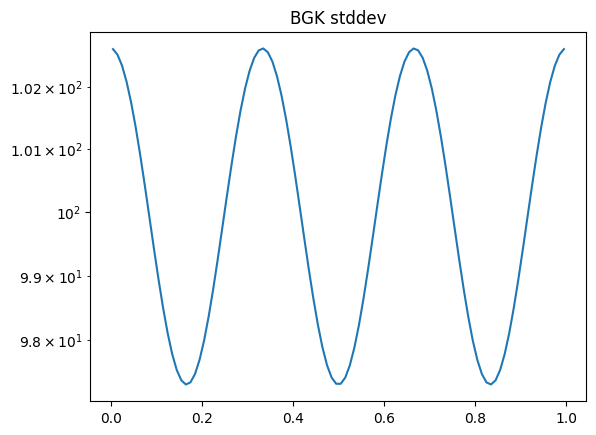

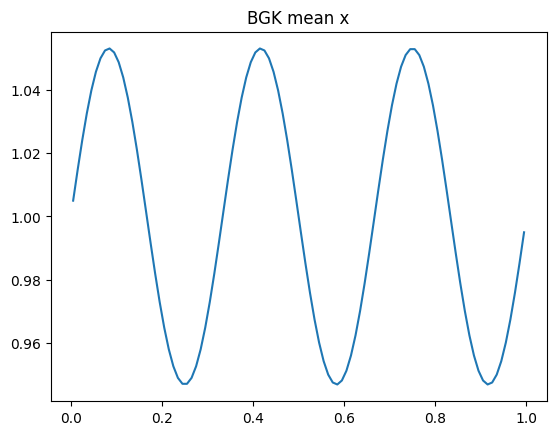

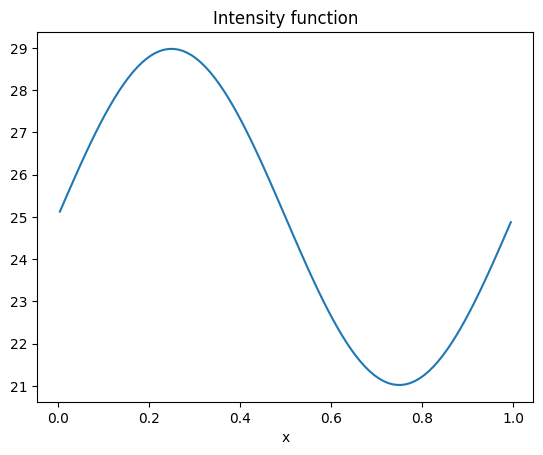

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
import math
import json
import subprocess
import time

config = {}

# Length of the domain
Lx = 1.0
Ly = 2.0
Lz = 2.0

# Number of cells in each direction
nx = 100
ny = 1
nz = 1

# Background parameters
ncells = nx * ny * nz
vol = Lx*Ly*Lz/nx/ny/nz

xval = np.linspace(1./nx/2., 1-1./nx/2., nx)
intensityfun = np.zeros(ncells)
for i in range(ncells):
    # intensityfun[i] = 1.0
    intensityfun[i] = (1.0 / (2.0 * np.pi) ) * np.sin(2.0 * np.pi * xval[i]) + 1.0

rate = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    rate[i] = (1.0 / (4.0 * np.pi) ) * 10.0**4 * np.sin(4.0 * np.pi * xval[i]) + 10.0**4

bgk_stddev = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    # bgk_stddev[i] = 10.0**2
    bgk_stddev[i] = np.sqrt((1.0 / (6.0 * np.pi) ) * 10.0**4 * np.cos(6.0 * np.pi * xval[i]) + 10.0**4)

bgk_mean_x = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    # bgk_mean_x[i] = 1.0
    bgk_mean_x[i] = (1.0 / (6.0 * np.pi) ) * np.sin(6.0 * np.pi * xval[i]) + 1.0

bgk_mean_y = np.zeros(ncells, dtype=np.float64)
bgk_mean_z = np.zeros(ncells, dtype=np.float64)

plt.figure()
plt.semilogy(xval, rate)
plt.title("Rate function")

plt.figure()
plt.semilogy(xval, bgk_stddev)
plt.title("BGK stddev")

plt.figure()
plt.plot(xval, bgk_mean_x)
plt.title("BGK mean x")

plt.figure()
plt.plot(xval, intensityfun / vol)
plt.title("Intensity function")
plt.xlabel("x")
plt.show()

Simulation took 138.44219732284546 seconds
{'grid_building_time': 5.235e-06, 'num_collisions': 2499456959, 'num_crossings': 2013127844, 'num_kd_steps': 0, 'num_kd_to_kinetic_switches': 0, 'total_particles': 9999950, 'total_time': 138.434641252, 'trace_time': 138.434636017}


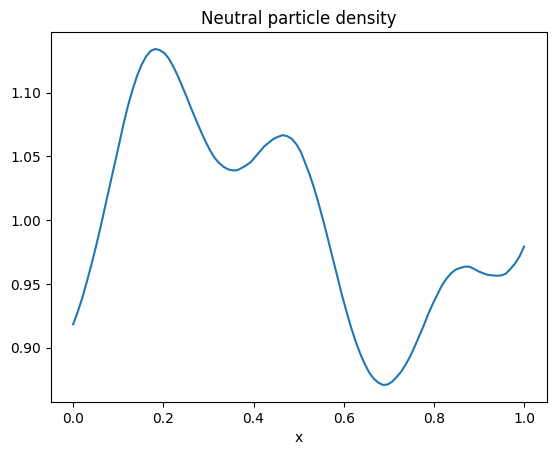

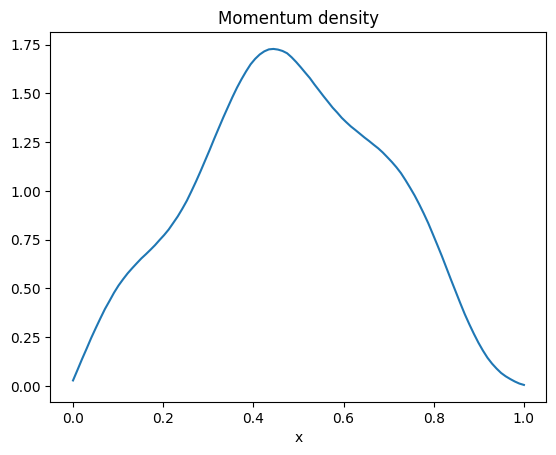

In [ ]:

config["mesh"] = {
    "type": "voxel",
    "Lx": Lx,
    "Ly": Ly,
    "Lz": Lz,
    "nx": nx,
    "ny": ny,
    "nz": nz
}

config["bgk_processes"] = [
    {
        "rate": rate.tolist(),
        "bgk_stddev": bgk_stddev.tolist(),
        "bgk_mean_x": bgk_mean_x.tolist(),
        "bgk_mean_y": bgk_mean_y.tolist(),
        "bgk_mean_z": bgk_mean_z.tolist()
    }
]

config["sources"] = []
for i in range(ncells):
    config["sources"].append(
        {
            "type": "volume",
            "intensity": intensityfun[i],
            "cell_idx": i,
            "vel_mean": [bgk_mean_x[i], bgk_mean_y[i], bgk_mean_z[i]],
            "vel_stddev": bgk_stddev[i],
            "n_particles": int(1e7*intensityfun[i]/sum(intensityfun)),
        }
    )

config["boundary_conditions"] = [
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
]

if "dt" in config:
    del config["dt"]

t_final = 0.025
# t_final = 0.00005
config["t_final"] = t_final

config["max_steps"] = 10000
config["seed"] = 0

# Run the simulation
inputstring = json.dumps(config)

with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
subprocess.check_output(["neptune-mc"]).decode("utf-8")
end_time = time.time()

print("Simulation took", end_time - start_time, "seconds")

with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

neutral_density = np.array(output["density"]) * vol / t_final

momentum_x = np.array(output["momentum_x"]) * vol / t_final

energy = np.array(output["energy"]) * vol / t_final

x = np.linspace(0,Lx,nx)


plt.plot(x, neutral_density)
# plt.plot(x, intensityfun)
plt.title("Neutral particle density")
plt.xlabel("x")
plt.show()

plt.plot(x, momentum_x)
plt.title("Momentum density")
plt.xlabel("x")
plt.show()

No input file specified, using default input.json and output.json
Running fluid solver with dt = 0.00135468

Simulation took 33.32811498641968 seconds


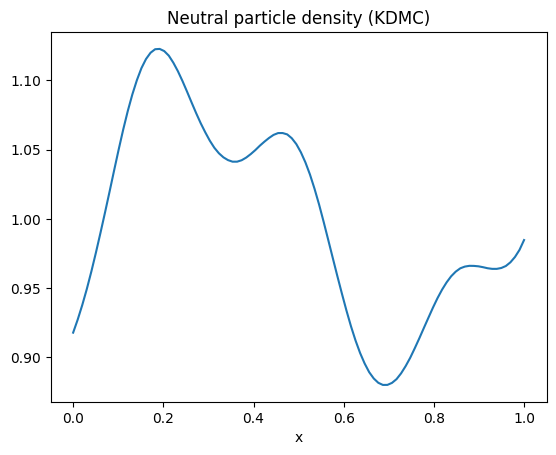

In [ ]:
##
## Part 2, KDMC
##

fluid_boundary_conditions = [
    {
        "alpha": -bgk_mean_x[0],
        "beta": -bgk_stddev[0]**2/ rate[0],
        "gamma": 0
    },
    {
        "alpha": -bgk_mean_y[0],
        "beta": -bgk_stddev[0]**2/ rate[0],
        "gamma": 0
    },
    {
        "alpha": -bgk_mean_z[0],
        "beta": -bgk_stddev[0]**2/ rate[0],
        "gamma": 0
    },
    {
        "alpha": bgk_mean_x[ncells-1],
        "beta": -bgk_stddev[ncells-1]**2/ rate[ncells-1],
        "gamma": 0
    },
    {
        "alpha": bgk_mean_y[ncells-1],
        "beta": -bgk_stddev[ncells-1]**2/ rate[ncells-1],
        "gamma": 0
    },
    {
        "alpha": bgk_mean_z[ncells-1],
        "beta": -bgk_stddev[ncells-1]**2/ rate[ncells-1],
        "gamma": 0
    },
]

config_kd = config.copy()

config_kd["fluid_boundary_conditions"] = fluid_boundary_conditions

config_kd["dt"] = t_final/10

config_kd["algorithm"] = "kdmc"

inputstring = json.dumps(config_kd)
with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
cmd_output = subprocess.check_output(["neptune-mc"]).decode("utf-8")
end_time = time.time()

print(cmd_output)

print("Simulation took", end_time - start_time, "seconds")

with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

neutral_density_kd = np.array(output["density"]) * vol / t_final
momentum_x_kd = np.array(output["momentum_x"]) * vol / t_final
energy_kd = np.array(output["energy"]) * vol / t_final


x = np.linspace(0,Lx,nx)

plt.plot(x, neutral_density_kd)
# plt.plot(x, intensityfun)
plt.title("Neutral particle density (KDMC)")
plt.xlabel("x")
plt.show()

In [ ]:

##
## Part 3, finite volume solver
##

fv_density = np.zeros(ncells, dtype=np.float64)

for i in range(ncells):
    fv_density[i] = intensityfun[i] / vol

diffusion_rate = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    diffusion_rate[i] = 1/rate[i]

diffusion_factor = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    diffusion_factor[i] = bgk_stddev[i]**2

config_fluid = config.copy()


config_fluid["density"] = fv_density.tolist()
config_fluid["diffusion_rate"] = diffusion_rate.tolist()
config_fluid["diffusion_factor"] = diffusion_factor.tolist()
config_fluid["advection_x"] = bgk_mean_x.tolist()
config_fluid["advection_y"] = bgk_mean_y.tolist()
config_fluid["advection_z"] = bgk_mean_z.tolist()
config_fluid["t_final"] = t_final
config_fluid["dt"] = 1.0e-3

config_fluid["boundary_conditions"] = fluid_boundary_conditions

inputstring = json.dumps(config_fluid)

with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
subprocess.check_output(["neptune-fv"]).decode("utf-8")
end_time = time.time()


with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

neutral_density_fv = np.array(output["density_integral"]) * vol / t_final
momentum_x_fv = np.array(output["momentum_x_integral"]) * vol / t_final
energy_fv = np.array(output["energy_integral"]) * vol / t_final




{'grid_building_time': 1.0588e-05, 'num_collisions': 0, 'num_crossings': 0, 'num_kd_steps': 0, 'num_kd_to_kinetic_switches': 0, 'total_particles': 0, 'total_time': 0.000616377, 'trace_time': 0.000605789}


In [ ]:

##
## Part 4, ARC-MC
##

config_ARCMC = config.copy()

config_ARCMC["algorithm"] = "arcmc"

ARCMC_M = 8
config_ARCMC["M"] = ARCMC_M

inputstring = json.dumps(config_ARCMC)
with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
subprocess.check_output(["neptune-mc"]).decode("utf-8")
end_time = time.time()

print("Simulation took", end_time - start_time, "seconds")

with open("output.json", "r") as f:
    outputstring = f.read()
output = json.loads(outputstring)

stats = output["stats"]
print(stats)

neutral_density_arcmc = np.array(output["density"]) * vol / t_final

momentum_x_arcmc = np.array(output["momentum_x"]) * vol / t_final

energy_arcmc = np.array(output["energy"]) * vol / t_final


Simulation took 41.96705079078674 seconds
{'grid_building_time': 6.398e-06, 'num_collisions': 2534437696, 'num_crossings': 946597654, 'num_kd_steps': 0, 'num_kd_to_kinetic_switches': 0, 'total_particles': 9999950, 'total_time': 41.959148526999996, 'trace_time': 41.959142129}


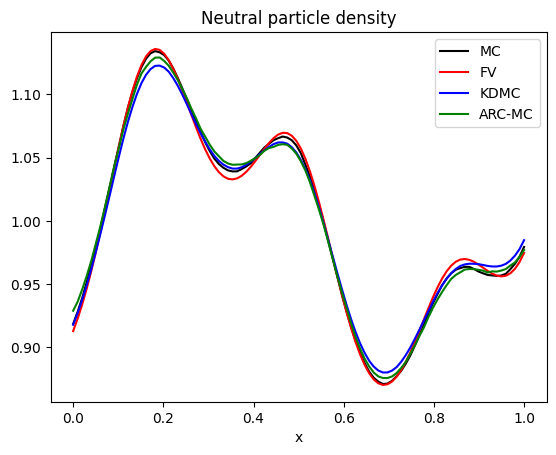

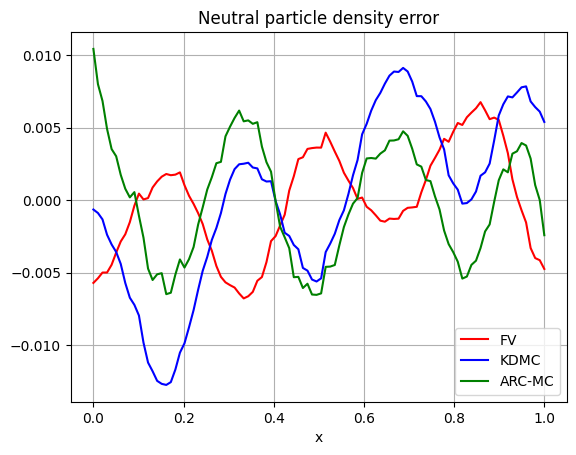

Wasserstein distance FV: 0.6069996825920517
Wasserstein distance KDMC: 1.4615410533995856
Wasserstein distance ARC-MC: 0.2137275030172608


In [ ]:

plt.figure()
plt.plot(x, neutral_density, label="MC", color="black")
plt.plot(x, neutral_density_fv, label="FV", color="red")
plt.plot(x, neutral_density_kd, label="KDMC", color="blue")
plt.plot(x, neutral_density_arcmc, label="ARC-MC", color="green")
# plt.plot(x, intensityfun)
plt.title("Neutral particle density")
plt.xlabel("x")
plt.legend()
plt.show()


plt.figure()
plt.plot(x, neutral_density_fv - neutral_density, label="FV", color="red")
plt.plot(x, neutral_density_kd - neutral_density, label="KDMC", color="blue")
plt.plot(x, neutral_density_arcmc - neutral_density, label="ARC-MC", color="green")
plt.grid()
# plt.plot(x, intensityfun)
plt.title("Neutral particle density error")
plt.xlabel("x")
plt.legend()
plt.show()

def wasserstein_2_distance(p, q):
    cdf_p = np.cumsum(p)
    cdf_q = np.cumsum(q)
    return np.linalg.norm(cdf_p - cdf_q)

# print wasserstein distances
wd_fv = wasserstein_2_distance(neutral_density, neutral_density_fv)
wd_kd = wasserstein_2_distance(neutral_density, neutral_density_kd)
wd_arcmc = wasserstein_2_distance(neutral_density, neutral_density_arcmc)

print("Wasserstein distance FV:", wd_fv)
print("Wasserstein distance KDMC:", wd_kd)
print("Wasserstein distance ARC-MC:", wd_arcmc)

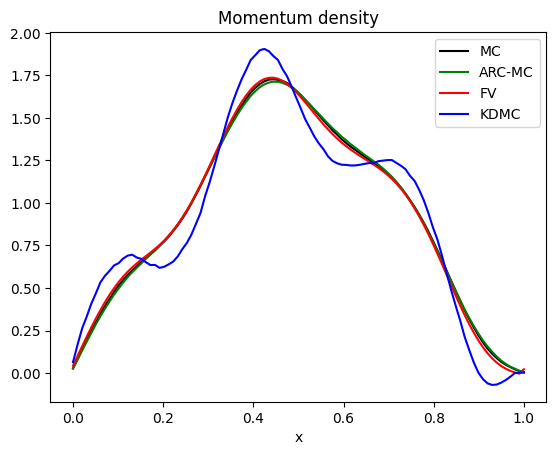

Wasserstein distance FV: 3.745482318995006
Wasserstein distance KDMC: 10.0774113649578
Wasserstein distance ARC-MC: 2.090223008129994


In [ ]:

plt.figure()
plt.plot(x, momentum_x, label="MC", color="black")
plt.plot(x, momentum_x_arcmc, label="ARC-MC", color="green")
plt.plot(x, momentum_x_fv, label="FV", color="red")
plt.plot(x, momentum_x_kd, label="KDMC", color="blue")
# plt.plot(x, intensityfun)
plt.title("Momentum density")
plt.xlabel("x")
plt.legend()
plt.show()


# print wasserstein distances
wd_fv = wasserstein_2_distance(momentum_x, momentum_x_fv)
wd_kd = wasserstein_2_distance(momentum_x, momentum_x_kd)
wd_arcmc = wasserstein_2_distance(momentum_x, momentum_x_arcmc)

print("Wasserstein distance FV:", wd_fv)
print("Wasserstein distance KDMC:", wd_kd)
print("Wasserstein distance ARC-MC:", wd_arcmc)

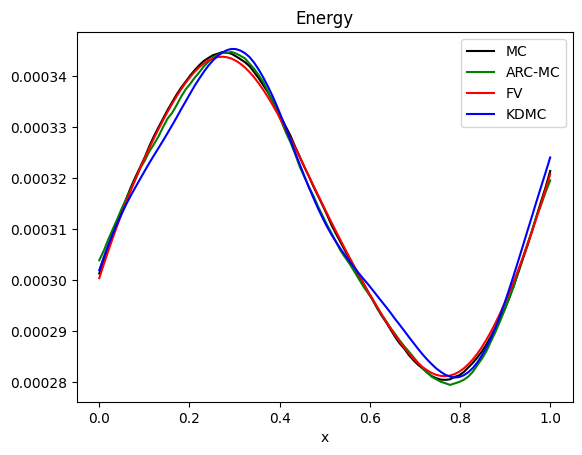

Wasserstein distance FV: 0.00017177970338605762
Wasserstein distance KDMC: 0.00041717314036298926
Wasserstein distance ARC-MC: 0.00031830056603836807


In [ ]:
plt.figure()
plt.plot(x, energy, label="MC", color="black")
plt.plot(x, energy_arcmc, label="ARC-MC", color="green")
plt.plot(x, energy_fv, label="FV", color="red")
plt.plot(x, energy_kd, label="KDMC", color="blue")
# plt.plot(x, energy_arcmc * (energy[20] / energy_arcmc[20]), label="ARC-MC (scaled with 1/E[W])")
# plt.plot(x, intensityfun)
plt.title("Energy")
plt.xlabel("x")
plt.legend()
plt.show()


# print wasserstein distances
wd_fv = wasserstein_2_distance(energy, energy_fv)
wd_kd = wasserstein_2_distance(energy, energy_kd)
wd_arcmc = wasserstein_2_distance(energy, energy_arcmc)

print("Wasserstein distance FV:", wd_fv)
print("Wasserstein distance KDMC:", wd_kd)
print("Wasserstein distance ARC-MC:", wd_arcmc)